In [2]:
%pip install -q "mlflow>=3.0,<4"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 3.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 40.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 35.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 35.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 9.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1

Registros originales: 569
Registros limpios: 569
Valores nulos: 0


2026/10/19 01:29:00 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/19 01:29:01 INFO mlflow.store.db.utils: Updating database tables
2026/10/19 01:29:07 INFO mlflow.tracking.fluent: Experiment with name 'Actividad5_Cancer_Mama_Final' does not exist. Creating a new experiment.



Entrenando: Regresion_Logistica


2026/10/19 01:29:12 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/19 01:29:12 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Mejores parámetros: {'modelo__C': 0.1, 'modelo__class_weight': None}
Accuracy: 0.9737
F1 macro: 0.9716
ROC-AUC: 0.9957

Entrenando: Random_Forest


2026/10/19 01:29:50 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/19 01:29:50 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Mejores parámetros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}
Accuracy: 0.9474
F1 macro: 0.9435
ROC-AUC: 0.9942

RESULTADOS FINALES


,modelo,accuracy,precision_macro,recall_macro,f1_macro,roc_auc,recall_maligno,latencia_ms,segundos_entrenamiento,mejores_parametros
0,Regresion_Logistica,0.973684,0.974106,0.969246,0.971583,0.995701,0.952381,0.018169,4.095871,"{""modelo__C"": 0.1, ""modelo__class_weight"": null}"
1,Random_Forest,0.947368,0.943452,0.943452,0.943452,0.994213,0.928571,0.075097,27.247759,"{""modelo__class_weight"": ""balanced"", ""modelo__..."



COMPARACIÓN ESTADÍSTICA
Prueba de Wilcoxon pareada sobre F1 macro en cinco grupos.
Estadístico: 2.0000
Valor p: 0.3750
Interpretar con cautela: solo se comparan cinco grupos.


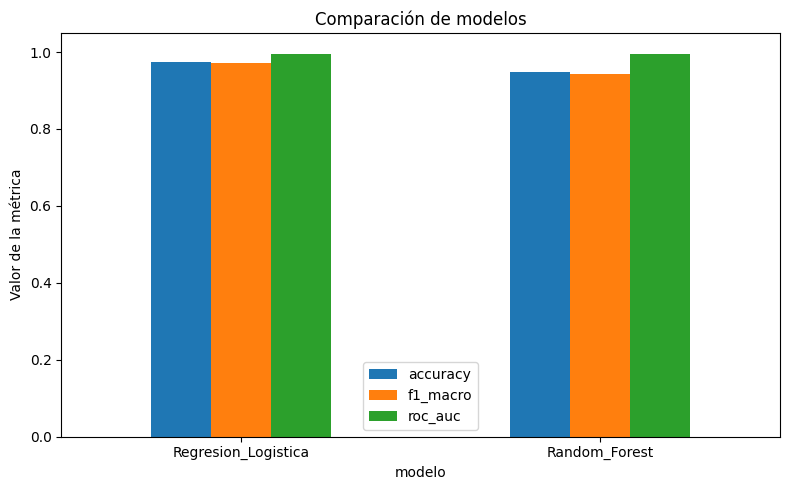

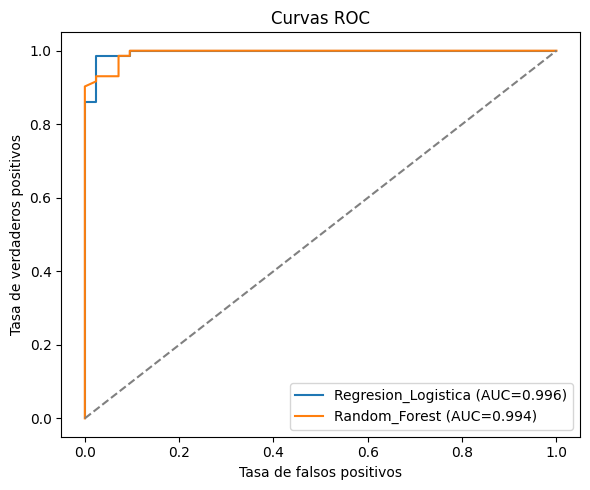

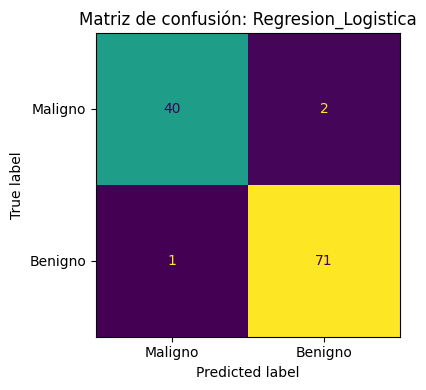

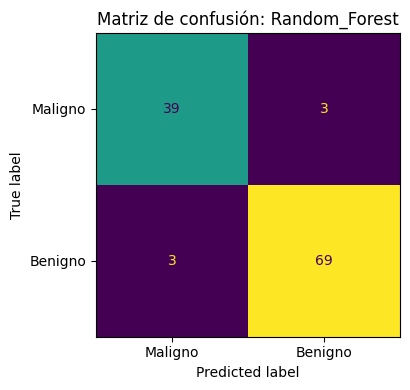


CORRIDAS REGISTRADAS EN MLFLOW


,tags.mlflow.runName,status,metrics.accuracy,metrics.f1_macro,metrics.roc_auc
0,Random_Forest,FINISHED,0.947368,0.943452,0.994213
1,Regresion_Logistica,FINISHED,0.973684,0.971583,0.995701


Total de corridas: 2

¡ENTRENAMIENTO TERMINADO!
Resultados guardados en: /content/Actividad5/resultados
Base de datos de MLflow: /content/Actividad5/mlflow.db


In [3]:
# ACTIVIDAD 5: Cáncer de mama de Wisconsin
# Comparación de Regresión Logística y Random Forest
# Uso académico. No utilizar para diagnosticar pacientes.

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn

from scipy.stats import wilcoxon
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, ConfusionMatrixDisplay, roc_curve
)

# 1. Crear carpetas
base = Path("/content/Actividad5")
for carpeta in [
    "datos/datos_ini", "datos/datos_limp", "resultados"
]:
    (base / carpeta).mkdir(parents=True, exist_ok=True)

# 2. Cargar dataset público
dataset = load_breast_cancer(as_frame=True)
df = dataset.data.copy()
df["diagnostico"] = dataset.target.map({
    0: "maligno",
    1: "benigno"
}).values

df.to_csv(base / "datos/datos_ini/dataset_original.csv", index=False)

# 3. Limpiar datos
limpio = df.drop_duplicates().dropna().copy()
limpio.to_csv(base / "datos/datos_limp/dataset_limpio.csv", index=False)

print("Registros originales:", len(df))
print("Registros limpios:", len(limpio))
print("Valores nulos:", int(limpio.isna().sum().sum()))

# 4. Separar datos
X = limpio.drop(columns=["diagnostico"])
y = limpio["diagnostico"].map({"maligno": 0, "benigno": 1}).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 5. Validación cruzada
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 6. Definir los dos modelos y sus parámetros
modelos = {
    "Regresion_Logistica": {
        "pipeline": Pipeline([
            ("escalado", StandardScaler()),
            ("modelo", LogisticRegression(max_iter=3000, random_state=42))
        ]),
        "parametros": {
            "modelo__C": [0.1, 1, 10],
            "modelo__class_weight": [None, "balanced"]
        }
    },
    "Random_Forest": {
        "pipeline": Pipeline([
            ("modelo", RandomForestClassifier(random_state=42, n_jobs=1))
        ]),
        "parametros": {
            "modelo__n_estimators": [100, 200],
            "modelo__max_depth": [None, 8],
            "modelo__min_samples_leaf": [1, 2],
            "modelo__class_weight": [None, "balanced"]
        }
    }
}

# 7. Configurar MLflow usando SQLite
db = base / "mlflow.db"
mlflow.set_tracking_uri(f"sqlite:///{db}")
mlflow.set_experiment("Actividad5_Cancer_Mama_Final")

resultados = []
scores_cv = {}
modelos_finales = {}

# 8. Entrenar, evaluar y registrar los modelos
for nombre, config in modelos.items():
    print("\nEntrenando:", nombre)
    inicio = time.perf_counter()

    busqueda = GridSearchCV(
        estimator=config["pipeline"],
        param_grid=config["parametros"],
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True
    )
    busqueda.fit(X_train, y_train)

    modelo = busqueda.best_estimator_
    pred = modelo.predict(X_test)
    prob = modelo.predict_proba(X_test)[:, 1]

    # Latencia promedio por registro
    t0 = time.perf_counter()
    for _ in range(10):
        modelo.predict(X_test)
    latencia = (time.perf_counter() - t0) / 10 / len(X_test) * 1000

    metricas = {
        "accuracy": float(accuracy_score(y_test, pred)),
        "precision_macro": float(precision_score(
            y_test, pred, average="macro", zero_division=0
        )),
        "recall_macro": float(recall_score(
            y_test, pred, average="macro", zero_division=0
        )),
        "f1_macro": float(f1_score(
            y_test, pred, average="macro", zero_division=0
        )),
        "roc_auc": float(roc_auc_score(y_test, prob)),
        "recall_maligno": float(recall_score(
            y_test, pred, pos_label=0, zero_division=0
        )),
        "latencia_ms": float(latencia),
        "segundos_entrenamiento": float(time.perf_counter() - inicio)
    }

    # Resultados de los cinco grupos de validación
    mejor_fila = busqueda.best_index_
    scores_cv[nombre] = np.array([
        busqueda.cv_results_[f"split{i}_test_score"][mejor_fila]
        for i in range(5)
    ])

    resultados.append({
        "modelo": nombre,
        **metricas,
        "mejores_parametros": json.dumps(
            busqueda.best_params_, ensure_ascii=False
        )
    })
    modelos_finales[nombre] = modelo

    # Registro de parámetros, métricas y modelo en MLflow
    with mlflow.start_run(run_name=nombre):
        mlflow.log_param("dataset", "Wisconsin Breast Cancer Diagnostic")
        mlflow.log_param("semilla", 42)
        mlflow.log_param("validacion", "StratifiedKFold de 5 grupos")
        mlflow.log_param("criterio_ajuste", "F1 macro")
        mlflow.log_param("registros_entrenamiento", len(X_train))
        mlflow.log_param("registros_prueba", len(X_test))

        for clave, valor in busqueda.best_params_.items():
            mlflow.log_param(clave, str(valor))

        mlflow.log_metrics(metricas)

        # Guardar el modelo en formato cloudpickle
        mlflow.sklearn.log_model(
            modelo,
            artifact_path="modelo",
            serialization_format="cloudpickle"
        )

    print("Mejores parámetros:", busqueda.best_params_)
    print("Accuracy:", round(metricas["accuracy"], 4))
    print("F1 macro:", round(metricas["f1_macro"], 4))
    print("ROC-AUC:", round(metricas["roc_auc"], 4))

# 9. Guardar y mostrar métricas
tabla = pd.DataFrame(resultados)
tabla.to_csv(base / "resultados/metricas_modelos.csv", index=False)

print("\nRESULTADOS FINALES")
display(tabla)

# 10. Comparación estadística exploratoria
a = scores_cv["Regresion_Logistica"]
b = scores_cv["Random_Forest"]

if np.allclose(a, b):
    estadistico, valor_p = 0.0, 1.0
else:
    prueba = wilcoxon(a, b, alternative="two-sided")
    estadistico, valor_p = float(prueba.statistic), float(prueba.pvalue)

texto = (
    "Prueba de Wilcoxon pareada sobre F1 macro en cinco grupos.\n"
    f"Estadístico: {estadistico:.4f}\n"
    f"Valor p: {valor_p:.4f}\n"
    "Interpretar con cautela: solo se comparan cinco grupos."
)
(base / "resultados/comparacion_estadistica.txt").write_text(
    texto, encoding="utf-8"
)
print("\nCOMPARACIÓN ESTADÍSTICA")
print(texto)

# 11. Gráfica comparativa
tabla.set_index("modelo")[["accuracy", "f1_macro", "roc_auc"]].plot(
    kind="bar", figsize=(8, 5)
)
plt.title("Comparación de modelos")
plt.ylabel("Valor de la métrica")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(base / "resultados/comparacion_modelos.png", dpi=150)
plt.show()
plt.close()

# 12. Curvas ROC
plt.figure(figsize=(6, 5))
for nombre, modelo in modelos_finales.items():
    prob = modelo.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{nombre} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curvas ROC")
plt.legend()
plt.tight_layout()
plt.savefig(base / "resultados/curvas_roc.png", dpi=150)
plt.show()
plt.close()

# 13. Matrices de confusión y predicciones
predicciones = pd.DataFrame({
    "diagnostico_real": y_test.map({0: "maligno", 1: "benigno"}).values
})

for nombre, modelo in modelos_finales.items():
    pred = modelo.predict(X_test)
    predicciones[nombre] = pd.Series(
        pred, index=y_test.index
    ).map({0: "maligno", 1: "benigno"}).values

    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred,
        display_labels=["Maligno", "Benigno"],
        ax=ax, colorbar=False
    )
    ax.set_title(f"Matriz de confusión: {nombre}")
    fig.tight_layout()
    fig.savefig(base / f"resultados/confusion_{nombre}.png", dpi=150)
    plt.show()
    plt.close(fig)

predicciones.to_csv(base / "resultados/predicciones.csv", index=False)

# 14. Metadatos de ejecución
metadata = {
    "dataset": "Wisconsin Breast Cancer Diagnostic",
    "fuente": "https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic",
    "registros_originales": int(len(df)),
    "registros_limpios": int(len(limpio)),
    "variables_predictoras": int(X.shape[1]),
    "semilla": 42,
    "modelos": list(modelos.keys()),
    "uso": "Académico; no utilizar para diagnóstico médico."
}
(base / "resultados/metadatos.json").write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

# 15. Recuperar las corridas de MLflow sin asumir el nombre de columnas
experimento = mlflow.get_experiment_by_name("Actividad5_Cancer_Mama_Final")
corridas = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id]
)
corridas.to_csv(base / "resultados/mlflow_corridas.csv", index=False)

print("\nCORRIDAS REGISTRADAS EN MLFLOW")
columnas = [
    "tags.mlflow.runName",
    "status",
    "metrics.accuracy",
    "metrics.f1_macro",
    "metrics.roc_auc"
]
disponibles = [c for c in columnas if c in corridas.columns]
display(corridas[disponibles])
print("Total de corridas:", len(corridas))

print("\n¡ENTRENAMIENTO TERMINADO!")
print("Resultados guardados en:", base / "resultados")
print("Base de datos de MLflow:", db)

In [4]:
#Descargar resultados
import os
import zipfile
from google.colab import files

base = "/content/Actividad5"
archivo_zip = "/content/resultados_actividad5.zip"

with zipfile.ZipFile(archivo_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for carpeta, subcarpetas, archivos in os.walk(base):
        subcarpetas[:] = [
            d for d in subcarpetas if d != "__pycache__"
        ]
        for archivo in archivos:
            ruta = os.path.join(carpeta, archivo)
            z.write(ruta, os.path.relpath(ruta, "/content"))

files.download(archivo_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>